findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' not found.
findfont: Font family 'AppleGothic' not found.
findfont: Font family 'Malgun Gothic' no

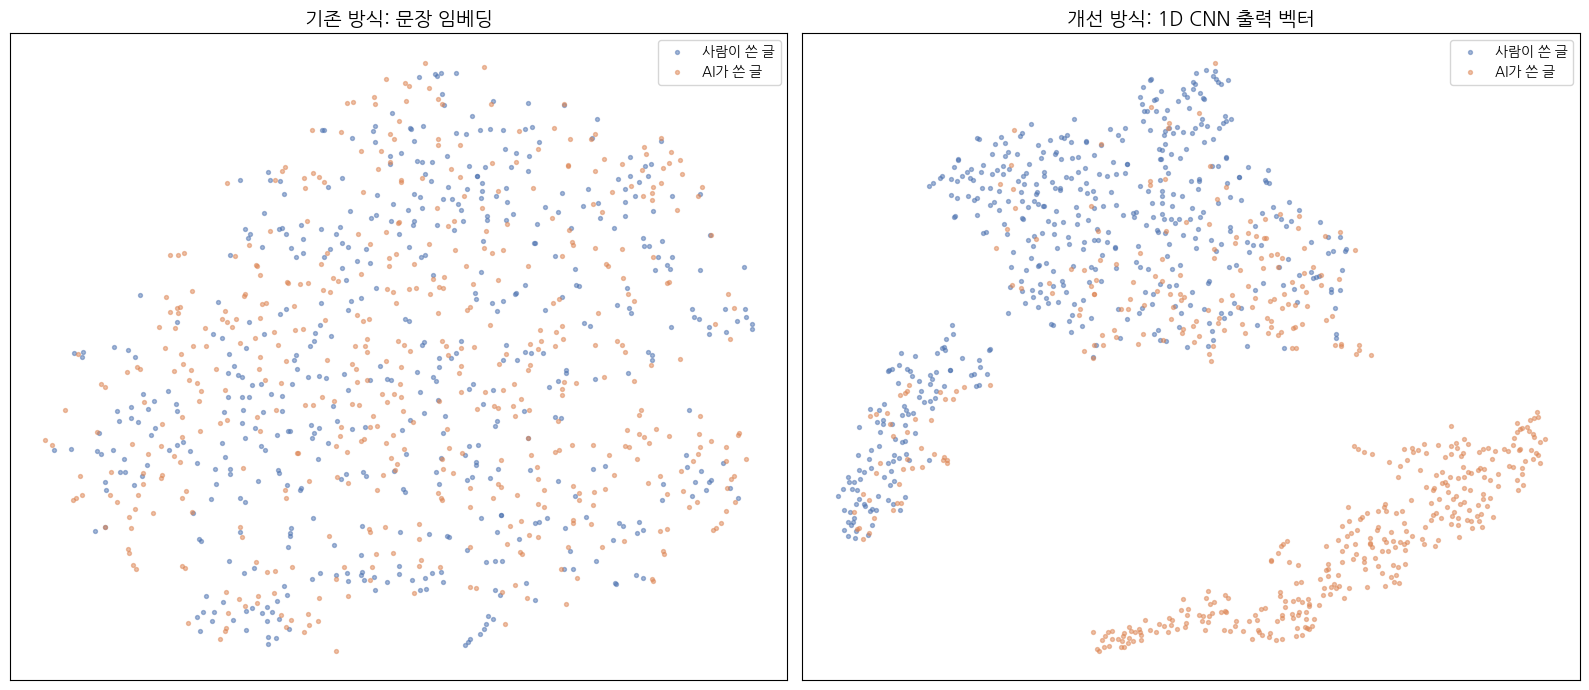

In [3]:
# ─────────────────────────────────────────────────────────────
# 임베딩 산점도 시각화
# 저장소 루트(llm_project/)에서 노트북 셀에 붙여 넣어 실행하세요.
#  1) 기존 방식: BERT 문장 임베딩(CLS 기반 pooler 출력)
#  2) 개선 방식: 1D CNN을 거쳐 분류 헤드로 들어가는 벡터 (학습된 .pth가 있을 때만)
# 결과: images/embedding_scatter.png
# ─────────────────────────────────────────────────────────────
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from transformers import AutoTokenizer, AutoModel, DataCollatorWithPadding
from torch.utils.data import DataLoader

from utils.preprocess import load_data_and_tokenize, balanced_train_test_split
from utils.models import (BertConv1dBinaryClassifier_MultiK,
                          masked_global_avgpool)

# ── 설정 ─────────────────────────────────────────
BASE = "klue/bert-base"
DATA_PATH = "./Text Classification Dataset/train.csv"
CNN_WEIGHTS = "./model_savefiles/BertConv1dBinaryClassifier_MultiK_1epoch_20251205.pth"  # 없으면 기존 방식만 그림
N_PER_CLASS = 500        # 클래스별로 뽑을 글 수
REDUCER = "tsne"         # "tsne" 또는 "pca"
SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"

# ── 데이터: 학습 때와 같은 방식으로 분할한 뒤 검증셋에서 샘플링 ──
tok = AutoTokenizer.from_pretrained(BASE)
ds = load_data_and_tokenize(tok, DATA_PATH)
_, ds_test = balanced_train_test_split(ds, ratio=0.3)
_, ds_val = balanced_train_test_split(ds_test, ratio=0.5)

def sample(ds, label, n):
    sub = ds.filter(lambda x: x["generated"] == label).shuffle(seed=SEED)
    return sub.select(range(min(n, len(sub))))

from datasets import concatenate_datasets
ds_s = concatenate_datasets([sample(ds_val, 0, N_PER_CLASS),
                             sample(ds_val, 1, N_PER_CLASS)])
loader = DataLoader(ds_s, batch_size=32, shuffle=False,
                    collate_fn=DataCollatorWithPadding(tokenizer=tok))

# ── 벡터 추출 ────────────────────────────────────
@torch.no_grad()
def extract(fn):
    vecs, labels = [], []
    for b in loader:
        ids = b["input_ids"].to(device)
        attn = b["attention_mask"].to(device)
        vecs.append(fn(ids, attn).cpu())
        labels.append(b["generated"])
    return torch.cat(vecs).numpy(), torch.cat(labels).numpy()

# 1) 기존 방식: 문장 임베딩 (AutoModelForSequenceClassification이 쓰는 pooler 출력)
bert = AutoModel.from_pretrained(BASE).to(device).eval()
sent_vec, y = extract(lambda ids, attn: bert(input_ids=ids, attention_mask=attn).pooler_output)

# 2) 개선 방식: 1D CNN 통과 후 풀링된 벡터 (forward에서 분류 헤드 직전까지)
cnn_vec = None
if os.path.exists(CNN_WEIGHTS):
    model = BertConv1dBinaryClassifier_MultiK(BASE).to(device)
    model.load_state_dict(torch.load(CNN_WEIGHTS, map_location=device))
    model.eval()

    def conv_vector(ids, attn):
        x = model.bert(input_ids=ids, attention_mask=attn).last_hidden_state.transpose(1, 2)
        for p in model.after_embbed:
            x = p(x, attn)
        for block in model.conv:
            x = block(x)
            for p in model.after_conv:
                x = p(x, attn)
        return masked_global_avgpool(x, attn)

    cnn_vec, _ = extract(conv_vector)
else:
    print(f"'{CNN_WEIGHTS}' 파일이 없어 기존 방식만 그립니다.")

# ── 2차원으로 축소 후 그리기 ──────────────────────
def reduce(v):
    if REDUCER == "pca":
        return PCA(n_components=2, random_state=SEED).fit_transform(v)
    return TSNE(n_components=2, random_state=SEED, init="pca", perplexity=30).fit_transform(v)

panels = [("기존 방식: 문장 임베딩", sent_vec)]
if cnn_vec is not None:
    panels.append(("개선 방식: 1D CNN 출력 벡터", cnn_vec))

plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False
fig, axes = plt.subplots(1, len(panels), figsize=(8 * len(panels), 7), squeeze=False)
for ax, (title, v) in zip(axes[0], panels):
    p = reduce(v)
    ax.scatter(p[y == 0, 0], p[y == 0, 1], s=8, alpha=0.5, label="사람이 쓴 글", c="#4C72B0")
    ax.scatter(p[y == 1, 0], p[y == 1, 1], s=8, alpha=0.5, label="AI가 쓴 글", c="#DD8452")
    ax.set_title(title, fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend()

plt.tight_layout()
os.makedirs("images", exist_ok=True)
plt.savefig("images/embedding_scatter.png", dpi=150, bbox_inches="tight")
plt.show()